# 04 — Avaliação e otimização dos modelos

Este notebook compara os classificadores através de métricas, matriz de confusão, curva ROC-AUC e validação cruzada. Inclui ainda um exemplo de otimização dos hiperparâmetros do Random Forest.


In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'scripts').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from scripts.data_prep import load_and_preprocess_data
from scripts.evaluate import evaluate_all_models, tune_random_forest
from scripts.train import train_all_classifiers

prepared = load_and_preprocess_data(str(PROJECT_ROOT / 'data' / 'cybersecurity_intrusion_data.csv'))
models = train_all_classifiers(prepared.X_train, prepared.y_train)


  -> A treinar Logistic Regression...
  -> A treinar Decision Tree...
  -> A treinar k-NN...
  -> A treinar Gaussian Naive Bayes...
  -> A treinar Multinomial Naive Bayes...
  -> A treinar Bernoulli Naive Bayes...
  -> A treinar SVM (RBF)...
  -> A treinar SVM (Polynomial)...
  -> A treinar Random Forest...
  -> A treinar AdaBoost...
  -> A treinar Gradient Boosting...
  -> A treinar XGBoost...


In [2]:
results, best_model, matrices = evaluate_all_models(models, prepared)
display(results)
print('Modelo selecionado:', best_model)
print('Matriz de confusão:', matrices[best_model])


,model,accuracy,precision,recall,f1_test,f1_cv_mean,f1_cv_std,roc_auc,f1_train,generalization_gap,diagnosis
0,Gradient Boosting,0.884172,1.000000,0.740914,0.851178,0.865481,0.010890,0.877978,0.866024,0.014845,balanced
1,Random Forest,0.884172,1.000000,0.740914,0.851178,0.865243,0.010731,0.881021,0.871837,0.020659,balanced
2,Decision Tree,0.884172,0.998423,0.742087,0.851379,0.862178,0.010461,0.874114,0.868081,0.016702,balanced
3,XGBoost,0.881027,0.986025,0.744431,0.848363,0.861725,0.011452,0.874227,0.861065,0.012702,balanced
4,SVM (RBF),0.868973,0.952024,0.744431,0.835526,0.847929,0.010849,0.877164,0.858954,0.023427,balanced
5,SVM (Polynomial),0.868973,0.967442,0.731536,0.833111,0.843879,0.012011,0.871703,0.853426,0.020315,balanced
6,AdaBoost,0.864256,1.000000,0.696366,0.821009,0.835491,0.013120,0.869348,0.835637,0.014628,balanced
7,k-NN,0.838574,0.938808,0.683470,0.791045,0.793439,0.009125,0.863663,0.825175,0.034130,balanced
8,Gaussian Naive Bayes,0.805556,0.852339,0.683470,0.758621,0.764498,0.010195,0.838358,0.765565,0.006945,balanced
9,Logistic Regression,0.740042,0.699441,0.733880,0.716247,0.724795,0.009530,0.805097,0.725709,0.009462,balanced


Modelo selecionado: Gradient Boosting
Matriz de confusão: [[1055, 0], [221, 632]]


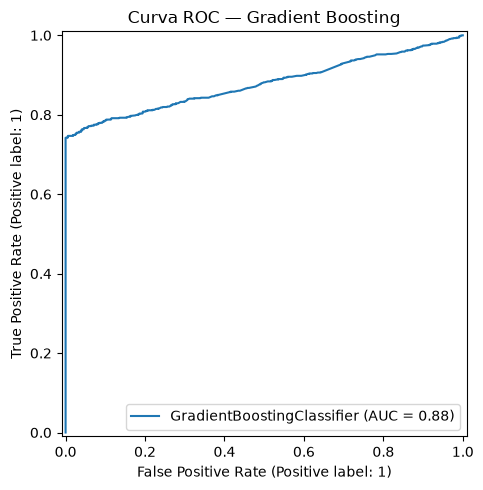

In [3]:
fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_estimator(models[best_model], prepared.X_test, prepared.y_test, ax=ax)
ax.set_title(f'Curva ROC — {best_model}')
plt.tight_layout()
plt.show()


In [4]:
search = tune_random_forest(prepared)
print('Melhores parâmetros:', search.best_params_)
print('Melhor F1-CV:', search.best_score_)


Melhores parâmetros: {'model__max_depth': 8, 'model__min_samples_leaf': 1, 'model__n_estimators': 250}
Melhor F1-CV: 0.8653214957158958
